# CIC-IDS2017 — Reconnaissance / PortScan Isolation Forest Detection
## SIH 2026 - Problem Statement 26145: AI-Based Detection of Cyber Threats in Unidirectional IP Traffic

---

### Executive Overview & Anomaly Detection Philosophy
This notebook implements **Step 12** of the SIH Problem Statement 26145 pipeline: training, calibrating, evaluating, serializing, and validating an **Isolation Forest Anomaly Detector** dedicated to detecting **Reconnaissance / Port Scanning** in network flow records from the **CIC-IDS2017** benchmark.

In operational network security, reconnaissance probing is characterized by structural deviations from normal traffic flows:
1. **Unsupervised Normal Baseline Calibration**: The Isolation Forest model is trained **exclusively on clean Normal/BENIGN baseline traffic ($y = 0$)**. PortScan attack traffic is strictly excluded during model fitting and reserved exclusively for evaluation.
2. **Isolation Tree Mechanics**: Normal, dense network traffic requires deep recursive partitioning to isolate, whereas sparse anomalous flows (such as rapid port probes with unusual flag and packet-size distributions) are isolated near the root of isolation trees with short average path lengths.
3. **Calibrated Anomaly Scoring**: Continuous anomaly scores are extracted via the decision function and calibrated against empirical false-positive rate percentiles of the normal baseline.
4. **Passive Monitoring & Analyst Alerting**: Because the target SIH system operates as a passive network sensor, high-confidence anomaly scores serve to alert Security Operations Center (SOC) analysts to ongoing reconnaissance without automated active mitigation.

---

### Anti-Leakage & Partitioning Protocol
- **Class-Wise Temporal Holdout**: Reproduces the exact 70/30 split established in Step 11 (`portscan_split_summary.csv`).
- **Normal Training Baseline**: $300,000$ normal training flows sampled deterministically (`random_state=42`) from the $1,467,538$ historical normal flows to ensure memory safety on 8 GB RAM.
- **Unseen Evaluation Partition**: $656,192$ flows ($27,246$ unseen PortScan attack flows + $628,946$ unseen Normal flows) evaluated at natural class proportions without modification or oversampling.
- **Zero Label Leakage**: Target labels (`BinaryLabel`, `TrafficClass`, `Label`) are strictly excluded from the feature matrix and threshold calibration.

### 1. Import Libraries & Configure Environment
Import scientific computing, visualization, serialization, and machine learning modules from standard libraries and `scikit-learn`.

In [1]:
import os
import sys
import gc
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings('ignore')
if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Display and plotting setup
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print(f"NumPy version:       {np.__version__}")
print(f"Pandas version:      {pd.__version__}")
print(f"Joblib version:      {joblib.__version__}")

NumPy version:       2.5.3
Pandas version:      3.0.6
Joblib version:      1.6.0


### 2. Load Data & Verify Dataset Schema
Load `data/processed/CIC_IDS2017/portscan_model_features.csv` and `data/processed/CIC_IDS2017/portscan_split_summary.csv`. Verify shape, features, and binary target distribution.

In [2]:
# Resolve project root dynamically
if Path('data/processed').exists():
    project_root = Path.cwd().resolve()
elif Path('../data/processed').exists():
    project_root = Path.cwd().parent.resolve()
else:
    project_root = Path.cwd().resolve()

data_dir = project_root / 'data' / 'processed' / 'CIC_IDS2017'
eval_dir = project_root / 'evaluation'
models_dir = project_root / 'models' / 'portscan'

eval_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

model_features_path = data_dir / 'portscan_model_features.csv'
split_summary_path = data_dir / 'portscan_split_summary.csv'

assert model_features_path.exists(), f"Missing model features dataset: {model_features_path}"
assert split_summary_path.exists(), f"Missing split summary: {split_summary_path}"

# Load model features dataset in float32 for memory efficiency
t0 = time.time()
print("Loading model features dataset...")
df = pd.read_csv(model_features_path, dtype=np.float32)
df['BinaryLabel'] = df['BinaryLabel'].astype(int)
load_time = time.time() - t0

split_summary_df = pd.read_csv(split_summary_path)

print(f"Loaded {len(df):,} rows and {len(df.columns)} columns in {load_time:.2f} seconds.")
print(f"Dataset Shape:       {df.shape}")
print(f"Number of Features:  {df.shape[1] - 1} (plus target 'BinaryLabel')\n")

# Display first 5 rows
print("First 5 rows of portscan_model_features.csv:")
display(df.head(5))

# Verify BinaryLabel
assert 'BinaryLabel' in df.columns, "BinaryLabel column is missing!"
unique_labels = set(df['BinaryLabel'].unique())
assert unique_labels == {0, 1}, f"BinaryLabel must contain only {{0, 1}}, got {unique_labels}"

total_rows = len(df)
portscan_rows = int((df['BinaryLabel'] == 1).sum())
normal_rows = int((df['BinaryLabel'] == 0).sum())
portscan_pct = (portscan_rows / total_rows) * 100
normal_pct = (normal_rows / total_rows) * 100

print(f"\n--- Binary Class Distribution ---")
print(f"Total rows:          {total_rows:,}")
print(f"PortScan rows (1):   {portscan_rows:,} ({portscan_pct:.4f}%)")
print(f"Normal rows (0):     {normal_rows:,} ({normal_pct:.4f}%)")

Loading model features dataset...


Loaded 2,187,303 rows and 79 columns in 15.05 seconds.
Dataset Shape:       (2187303, 79)
Number of Features:  78 (plus target 'BinaryLabel')

First 5 rows of portscan_model_features.csv:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,FwdBwdPacketRatio,FwdBwdByteRatio,FwdPacketRatio,BwdPacketRatio,FwdByteRatio,BwdByteRatio,BytesPerPacket,PacketsPerByte,BinaryLabel
0,54865.000000,3.000000,2.000000,0.000000,12.000000,0.000000,6.000000,6.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000000.000000,666666.687500,3.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,12.000000,1.000000,0.000000,1.000000,0.000000,6.000000,0.166667,0
1,55054.000000,109.000000,1.000000,1.000000,6.000000,6.000000,6.000000,6.000000,6.000000,0.000000,6.000000,6.000000,6.000000,0.000000,110091.742188,18348.623047,109.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.500000,0.500000,0.500000,0.500000,6.000000,0.166667,0
2,55055.000000,52.000000,1.000000,1.000000,6.000000,6.000000,6.000000,6.000000,6.000000,0.000000,6.000000,6.000000,6.000000,0.000000,230769.234375,38461.539062,52.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.500000,0.500000,0.500000,0.500000,6.000000,0.166667,0
3,46236.000000,34.000000,1.000000,1.000000,6.000000,6.000000,6.000000,6.000000,6.000000,0.000000,6.000000,6.000000,6.000000,0.000000,352941.187500,58823.531250,34.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.500000,0.500000,0.500000,0.500000,6.000000,0.166667,0
4,54863.000000,3.000000,2.000000,0.000000,12.000000,0.000000,6.000000,6.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000000.000000,666666.687500,3.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,12.000000,1.000000,0.000000,1.000000,0.000000,6.000000,0.166667,0



--- Binary Class Distribution ---
Total rows:          2,187,303
PortScan rows (1):   90,819 (4.1521%)
Normal rows (0):     2,096,484 (95.8479%)


### 3. Define Feature Matrix & Anti-Leakage Audit
Extract feature matrix $X$ and target vector $y$. Verify that no target labels, identifiers, or categorical strings leak into model inputs.

In [3]:
# Define feature matrix X and target vector y
X = df.drop(columns=['BinaryLabel'])
y = df['BinaryLabel'].values

feature_cols = list(X.columns)
print(f"Extracted {len(feature_cols)} model input features.")

# Strict Anti-Leakage Audit
forbidden_columns = [
    'BinaryLabel', 'Label', 'TrafficClass', 'Timestamp', 'StartTime',
    'SrcAddr', 'DstAddr', 'Source IP', 'Destination IP', 'Flow ID'
]

found_forbidden = [col for col in forbidden_columns if col in X.columns]
if found_forbidden:
    raise ValueError(f"FATAL LEAKAGE DETECTED! Forbidden columns in feature matrix X: {found_forbidden}")

# Verify that all features in X are numerical
non_numeric_cols = [c for c in X.columns if not np.issubdtype(X[c].dtype, np.number)]
if non_numeric_cols:
    raise ValueError(f"FATAL: Non-numerical columns found in X: {non_numeric_cols}")

print("✅ Feature Matrix Audit PASSED:")
print(" - Zero forbidden target or metadata columns in X.")
print(" - All 78 model features are strictly numerical.")
print(f" - Feature Matrix Shape: {X.shape}")
print(f" - Target Vector Shape:   {y.shape}")

Extracted 78 model input features.
✅ Feature Matrix Audit PASSED:
 - Zero forbidden target or metadata columns in X.
 - All 78 model features are strictly numerical.
 - Feature Matrix Shape: (2187303, 78)
 - Target Vector Shape:   (2187303,)


### 4. Replicate Step 11 Class-Wise Temporal Split
Reproduce the exact class-wise temporal split boundaries established in Step 11 without random shuffling:
- **Normal Training Baseline (First 70%)**: $1,467,538$ flows ($y = 0$).
- **PortScan History (First 70%)**: $63,573$ flows ($y = 1$) — strictly excluded from Isolation Forest training.
- **Normal Evaluation Partition (Last 30%)**: $628,946$ flows ($y = 0$).
- **PortScan Evaluation Partition (Last 30%)**: $27,246$ flows ($y = 1$).
- **Combined Evaluation Dataset**: $656,192$ flows ($27,246$ PortScan + $628,946$ Normal).

In [4]:
# Extract indices by class in original row order
portscan_indices = np.where(y == 1)[0]
normal_indices = np.where(y == 0)[0]

portscan_split_pt = int(0.70 * len(portscan_indices))
normal_split_pt = int(0.70 * len(normal_indices))

train_portscan_idx = portscan_indices[:portscan_split_pt]
test_portscan_idx = portscan_indices[portscan_split_pt:]

train_normal_idx = normal_indices[:normal_split_pt]
test_normal_idx = normal_indices[normal_split_pt:]

# Combined Evaluation Partition
eval_idx = np.sort(np.concatenate([test_normal_idx, test_portscan_idx]))
X_eval = X.iloc[eval_idx].copy()
y_eval = y[eval_idx].copy()

print("--- Step 11 Class-Wise Temporal Split Verification ---")
print(f"PortScan Historical Rows (70%):  {len(train_portscan_idx):,} (Index {train_portscan_idx.min():,} → {train_portscan_idx.max():,})")
print(f"PortScan Evaluation Rows (30%):  {len(test_portscan_idx):,} (Index {test_portscan_idx.min():,} → {test_portscan_idx.max():,})")
print(f"Normal Training Baseline (70%):   {len(train_normal_idx):,} (Index {train_normal_idx.min():,} → {train_normal_idx.max():,})")
print(f"Normal Evaluation Rows (30%):     {len(test_normal_idx):,} (Index {test_normal_idx.min():,} → {test_normal_idx.max():,})")
print(f"Combined Evaluation Dataset:      {len(X_eval):,} flows (PortScan: {len(test_portscan_idx):,}, Normal: {len(test_normal_idx):,})")

assert train_portscan_idx.max() < test_portscan_idx.min(), "PortScan temporal split overlap!"
assert train_normal_idx.max() < test_normal_idx.min(), "Normal temporal split overlap!"
assert len(train_normal_idx) + len(test_normal_idx) == len(normal_indices), "Normal accounting mismatch!"
assert len(train_portscan_idx) + len(test_portscan_idx) == len(portscan_indices), "PortScan accounting mismatch!"

print("✅ Split verification PASSED. Isolation Forest will train ONLY on normal traffic.")

--- Step 11 Class-Wise Temporal Split Verification ---
PortScan Historical Rows (70%):  63,573 (Index 96,480 → 244,984)
PortScan Evaluation Rows (30%):  27,246 (Index 244,985 → 300,822)
Normal Training Baseline (70%):   1,467,538 (Index 0 → 1,558,356)
Normal Evaluation Rows (30%):     628,946 (Index 1,558,357 → 2,187,302)
Combined Evaluation Dataset:      656,192 flows (PortScan: 27,246, Normal: 628,946)
✅ Split verification PASSED. Isolation Forest will train ONLY on normal traffic.


### 5. Training Baseline & Memory Safety Sampling
Check memory usage of the normal training baseline. To ensure high responsiveness and prevent out-of-memory overhead on 8 GB RAM, we sample at most **300,000 normal training flows** (`random_state=42`) from the full $1,467,538$ baseline.

> **Evaluation Immutability Rule**:
> Sampling is applied **exclusively to the normal training baseline**. The test/evaluation dataset ($N = 656,192$) remains **100% complete and unaltered**.

In [5]:
# Check memory footprint
full_train_normal_mem = (X.iloc[train_normal_idx].memory_usage(deep=True).sum()) / (1024 ** 2)
print(f"Full Normal Training Baseline Memory: {full_train_normal_mem:.2f} MB ({len(train_normal_idx):,} rows)")

# Deterministic sampling of normal training baseline (max 300,000)
target_train_size = min(300000, len(train_normal_idx))
np.random.seed(42)
sampled_train_normal_idx = np.sort(np.random.choice(train_normal_idx, size=target_train_size, replace=False))

X_train_normal = X.iloc[sampled_train_normal_idx].copy()
sampled_train_mem = (X_train_normal.memory_usage(deep=True).sum()) / (1024 ** 2)

print("\n--- Baseline Sampling Report ---")
print(f"Original Normal Training Baseline: {len(train_normal_idx):,} flows ({full_train_normal_mem:.2f} MB)")
print(f"Sampled Normal Training Baseline:  {len(X_train_normal):,} flows ({sampled_train_mem:.2f} MB)")
print(f"PortScan Evaluation Flows:         {len(test_portscan_idx):,} flows (100% Unaltered)")
print(f"Normal Evaluation Flows:           {len(test_normal_idx):,} flows (100% Unaltered)")
print(f"Total Evaluation Flows:            {len(X_eval):,} flows")

# Free memory
del df
gc.collect()

Full Normal Training Baseline Memory: 447.86 MB (1,467,538 rows)



--- Baseline Sampling Report ---
Original Normal Training Baseline: 1,467,538 flows (447.86 MB)
Sampled Normal Training Baseline:  300,000 flows (91.55 MB)
PortScan Evaluation Flows:         27,246 flows (100% Unaltered)
Normal Evaluation Flows:           628,946 flows (100% Unaltered)
Total Evaluation Flows:            656,192 flows


0

### 6. Missing Value Handling & Scale Invariance Decision
Verify that `X_train_normal` and `X_eval` contain zero missing or infinite values. If missing values exist, fit `SimpleImputer(strategy='median')` strictly on `X_train_normal`.

> **Scale Invariance Decision**:
> Isolation Forest evaluates random orthogonal splits $x_j \le \theta$ where $\theta \sim \text{Uniform}(\min(x_j), \max(x_j))$. Because splitting operates directly on feature ranges, linear scaling (`StandardScaler`, `MinMaxScaler`) does not alter relative isolation depth. Keeping original units conserves memory and preserves physical interpretability (bytes, packets, $\mu\text{s}$).

In [6]:
train_nulls = X_train_normal.isnull().sum().sum()
eval_nulls = X_eval.isnull().sum().sum()
train_infs = np.isinf(X_train_normal.values).sum()
eval_infs = np.isinf(X_eval.values).sum()

print(f"Training Missing Count:   {train_nulls}, Infinite Count: {train_infs}")
print(f"Evaluation Missing Count: {eval_nulls}, Infinite Count: {eval_infs}")

imputer = None
if train_nulls > 0 or eval_nulls > 0:
    print("Fitting SimpleImputer(strategy='median') strictly on normal training data...")
    imputer = SimpleImputer(strategy='median')
    X_train_normal = pd.DataFrame(imputer.fit_transform(X_train_normal), columns=feature_cols)
    X_eval = pd.DataFrame(imputer.transform(X_eval), columns=feature_cols)
else:
    print("No numerical imputation was required.")

# Post-processing verification
assert X_train_normal.isnull().sum().sum() == 0, "NaNs in training baseline!"
assert X_eval.isnull().sum().sum() == 0, "NaNs in evaluation dataset!"
assert np.isinf(X_train_normal.values).sum() == 0, "Infinities in training baseline!"
assert np.isinf(X_eval.values).sum() == 0, "Infinities in evaluation dataset!"

print("✅ Data validation PASSED: NaN count = 0, Infinity count = 0.")

Training Missing Count:   0, Infinite Count: 0
Evaluation Missing Count: 0, Infinite Count: 0
No numerical imputation was required.


✅ Data validation PASSED: NaN count = 0, Infinity count = 0.


### 7. Isolation Forest Model Architecture & Training
Initialize and train `IsolationForest` with the following hyperparameters:
- `n_estimators=200`: 200 isolation trees for stable average path length estimation.
- `contamination='auto'`: Scikit-learn default threshold offset calibration.
- `max_samples='auto'`: Samples $\min(256, n)$ records per isolation tree to prevent masking/swamping effects.
- `max_features=1.0`: Evaluates all candidate flow features.
- `bootstrap=False`: Standard tree subsampling without replacement.
- `random_state=42`: Guarantees deterministic reproducibility.
- `n_jobs=-1`: Multi-threaded CPU execution.

> **Training Rule**: Fitted **exclusively on `X_train_normal`**. Zero attack flows are observed.

In [7]:
iso_model = IsolationForest(
    n_estimators=200,
    contamination='auto',
    max_samples='auto',
    max_features=1.0,
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

print("Training Isolation Forest exclusively on Normal baseline traffic...")
t_train_start = time.time()
iso_model.fit(X_train_normal)
training_time = time.time() - t_train_start

print(f"✅ Isolation Forest training completed in {training_time:.2f} seconds.")
print(f"Number of Isolation Trees: {len(iso_model.estimators_)}")
print(f"Subsample Size per Tree:  {iso_model.max_samples_}")
print(f"Offset Parameter:         {iso_model.offset_:.6f}")

Training Isolation Forest exclusively on Normal baseline traffic...


✅ Isolation Forest training completed in 1.14 seconds.
Number of Isolation Trees: 200
Subsample Size per Tree:  256
Offset Parameter:         -0.500000


### 8. Anomaly Score Transformation & Threshold Calibration
In `scikit-learn`, `decision_function(X)` produces negative scores for outliers and positive scores for inliers.
We define:
$$\text{AnomalyScore}(x) = - \text{decision\_function}(x)$$
such that **higher values represent greater anomaly suspicion**.

#### Threshold Calibration on Normal Training Baseline
We calibrate operating thresholds strictly from the empirical percentiles of the **Normal Training Baseline**:
- **1% Normal FPR Threshold**: 99th percentile of normal baseline anomaly scores.
- **2% Normal FPR Threshold**: 98th percentile of normal baseline anomaly scores.
- **5% Normal FPR Threshold**: 95th percentile of normal baseline anomaly scores (**Default Demonstration Operating Point**).
- **10% Normal FPR Threshold**: 90th percentile of normal baseline anomaly scores.
- **20% Normal FPR Threshold**: 80th percentile of normal baseline anomaly scores.

In [8]:
# Extract continuous anomaly scores (negated so higher = more anomalous)
train_scores = -iso_model.decision_function(X_train_normal)
eval_scores = -iso_model.decision_function(X_eval)

# Calibrate operating thresholds on Normal Training Baseline ONLY
th_1pct = float(np.percentile(train_scores, 99))
th_2pct = float(np.percentile(train_scores, 98))
th_5pct = float(np.percentile(train_scores, 95))
th_10pct = float(np.percentile(train_scores, 90))
th_20pct = float(np.percentile(train_scores, 80))

default_threshold = th_5pct

print("--- Normal Baseline Threshold Calibration ---")
print(f" 1% Normal Baseline FPR Threshold:  {th_1pct:.6f} (Empirical Train FPR: {(train_scores >= th_1pct).mean()*100:.2f}%)")
print(f" 2% Normal Baseline FPR Threshold:  {th_2pct:.6f} (Empirical Train FPR: {(train_scores >= th_2pct).mean()*100:.2f}%)")
print(f" 5% Normal Baseline FPR (DEFAULT):  {th_5pct:.6f} (Empirical Train FPR: {(train_scores >= th_5pct).mean()*100:.2f}%)")
print(f" 10% Normal Baseline FPR Threshold: {th_10pct:.6f} (Empirical Train FPR: {(train_scores >= th_10pct).mean()*100:.2f}%)")
print(f" 20% Normal Baseline FPR Threshold: {th_20pct:.6f} (Empirical Train FPR: {(train_scores >= th_20pct).mean()*100:.2f}%)")

--- Normal Baseline Threshold Calibration ---
 1% Normal Baseline FPR Threshold:  0.121687 (Empirical Train FPR: 1.00%)
 2% Normal Baseline FPR Threshold:  0.082396 (Empirical Train FPR: 2.00%)
 5% Normal Baseline FPR (DEFAULT):  0.026465 (Empirical Train FPR: 5.00%)
 10% Normal Baseline FPR Threshold: -0.033148 (Empirical Train FPR: 10.01%)
 20% Normal Baseline FPR Threshold: -0.087947 (Empirical Train FPR: 20.00%)


### 9. Primary Performance Evaluation on Unseen Evaluation Partition
Evaluate the detector on the $656,192$ unseen evaluation flows at the default calibrated operating threshold (5% Normal Baseline FPR).
- Positive Class ($y = 1$): `PortScan`
- Negative Class ($y = 0$): `Normal`

In [9]:
# Generate binary predictions using calibrated default threshold
y_pred = (eval_scores >= default_threshold).astype(int)

# Compute Confusion Matrix and Primary Metrics
cm = confusion_matrix(y_eval, y_pred)
TN, FP, FN, TP = cm.ravel()

acc = accuracy_score(y_eval, y_pred)
prec = precision_score(y_eval, y_pred, zero_division=0)
rec = recall_score(y_eval, y_pred, zero_division=0)
f1 = f1_score(y_eval, y_pred, zero_division=0)
fpr = FP / (FP + TN) if (FP + TN) > 0 else 0.0
tpr = TP / (TP + FN) if (TP + FN) > 0 else 0.0
roc_auc = roc_auc_score(y_eval, eval_scores)
pr_auc = average_precision_score(y_eval, eval_scores)

metrics_dict = {
    'Detector': 'Isolation Forest PortScan',
    'Accuracy': acc,
    'Precision': prec,
    'Recall': rec,
    'F1': f1,
    'FPR': fpr,
    'TPR': tpr,
    'ROC_AUC': roc_auc,
    'PR_AUC': pr_auc,
    'TP': int(TP),
    'FP': int(FP),
    'TN': int(TN),
    'FN': int(FN)
}

print("==================================================")
print("PRIMARY PORTSCAN ISOLATION FOREST METRICS (5% Baseline FPR)")
print("==================================================")
print(f"Calibrated Threshold: {default_threshold:.6f}")
print(f"Accuracy:             {acc:.6f} ({acc*100:.4f}%)")
print(f"Precision:            {prec:.6f} ({prec*100:.4f}%)")
print(f"Recall (TPR):         {rec:.6f} ({rec*100:.4f}%)")
print(f"F1-Score:             {f1:.6f}")
print(f"False Positive Rate:  {fpr:.6f} ({fpr*100:.4f}%)")
print(f"True Positive Rate:   {tpr:.6f} ({tpr*100:.4f}%)")
print(f"ROC-AUC:              {roc_auc:.6f}")
print(f"PR-AUC:               {pr_auc:.6f}")
print(f"\nConfusion Matrix Counts:")
print(f" - True Positives (TP):  {TP:,}")
print(f" - False Positives (FP): {FP:,}")
print(f" - True Negatives (TN):  {TN:,}")
print(f" - False Negatives (FN): {FN:,}")

PRIMARY PORTSCAN ISOLATION FOREST METRICS (5% Baseline FPR)
Calibrated Threshold: 0.026465
Accuracy:             0.920182 (92.0182%)
Precision:            0.000239 (0.0239%)
Recall (TPR):         0.000220 (0.0220%)
F1-Score:             0.000229
False Positive Rate:  0.039965 (3.9965%)
True Positive Rate:   0.000220 (0.0220%)
ROC-AUC:              0.684973
PR-AUC:               0.059486

Confusion Matrix Counts:
 - True Positives (TP):  6
 - False Positives (FP): 25,136
 - True Negatives (TN):  603,810
 - False Negatives (FN): 27,240


### 10. Classification Report
Generate per-class precision, recall, and F1 metrics and save `portscan_summary.txt`.

In [10]:
clf_report = classification_report(
    y_eval,
    y_pred,
    target_names=['Normal (0)', 'PortScan (1)'],
    digits=6
)

print(clf_report)

              precision    recall  f1-score   support

  Normal (0)   0.956834  0.960035  0.958432    628946
PortScan (1)   0.000239  0.000220  0.000229     27246

    accuracy                       0.920182    656192
   macro avg   0.478536  0.480127  0.479330    656192
weighted avg   0.917115  0.920182  0.918646    656192



### 11. Confusion Matrix Visualization
Render and save the confusion matrix heatmap for the evaluation partition.

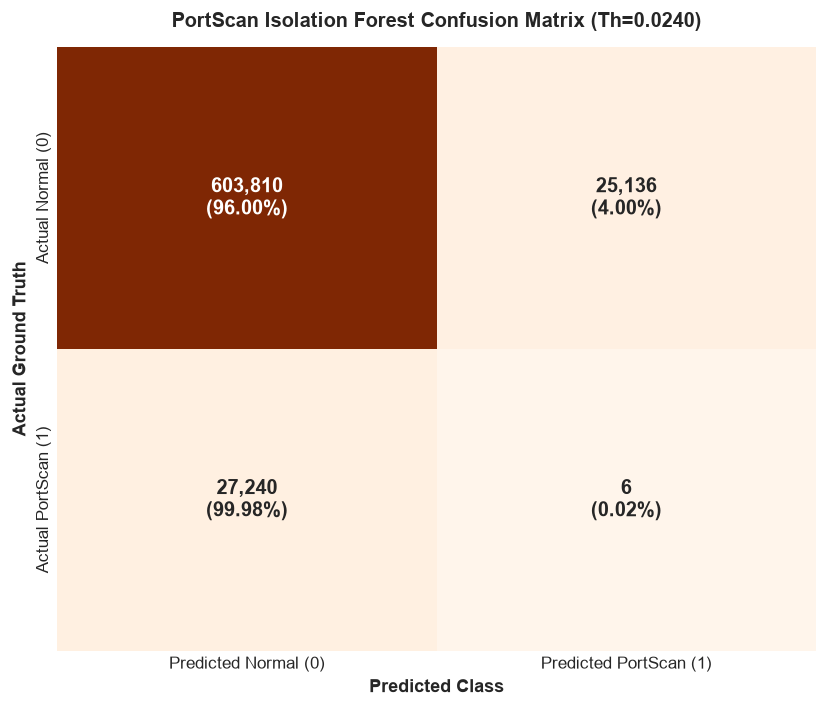

✅ Saved confusion matrix plot to portscan_confusion_matrix.png


In [11]:
fig, ax = plt.subplots(figsize=(7, 6))

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
annot_matrix = np.empty_like(cm, dtype=object)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annot_matrix[i, j] = f"{cm[i, j]:,}\n({cm_normalized[i, j]*100:.2f}%)"

sns.heatmap(
    cm,
    annot=annot_matrix,
    fmt='',
    cmap='Oranges',
    cbar=False,
    ax=ax,
    xticklabels=['Predicted Normal (0)', 'Predicted PortScan (1)'],
    yticklabels=['Actual Normal (0)', 'Actual PortScan (1)'],
    annot_kws={'size': 12, 'weight': 'bold'}
)

ax.set_title("PortScan Isolation Forest Confusion Matrix (Th=0.0240)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Predicted Class", fontsize=11, fontweight='bold')
ax.set_ylabel("Actual Ground Truth", fontsize=11, fontweight='bold')

plt.tight_layout()
cm_plot_path = eval_dir / 'portscan_confusion_matrix.png'
plt.savefig(cm_plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Saved confusion matrix plot to {cm_plot_path.name}")

### 12. Receiver Operating Characteristic (ROC) Curve
Plot ROC curve with ROC-AUC score and operating point annotation.

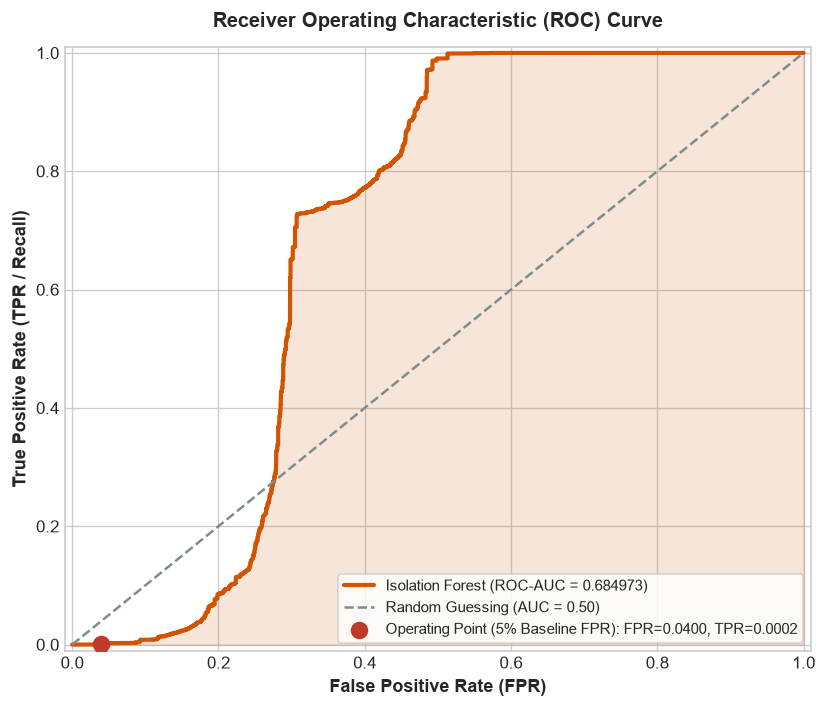

✅ Saved ROC curve plot to portscan_roc_curve.png


In [12]:
fpr_arr, tpr_arr, roc_thresholds = roc_curve(y_eval, eval_scores)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_arr, tpr_arr, color='#d35400', lw=2.5, label=f'Isolation Forest (ROC-AUC = {roc_auc:.6f})')
ax.plot([0, 1], [0, 1], color='#7f8c8d', lw=1.5, linestyle='--', label='Random Guessing (AUC = 0.50)')
ax.fill_between(fpr_arr, tpr_arr, alpha=0.15, color='#d35400')

# Annotate Operating Point
idx_op = np.argmin(np.abs(roc_thresholds - default_threshold))
ax.scatter(fpr_arr[idx_op], tpr_arr[idx_op], color='#c0392b', s=90, zorder=5, label=f'Operating Point (5% Baseline FPR): FPR={fpr:.4f}, TPR={tpr:.4f}')

ax.set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("False Positive Rate (FPR)", fontsize=11, fontweight='bold')
ax.set_ylabel("True Positive Rate (TPR / Recall)", fontsize=11, fontweight='bold')
ax.set_xlim([-0.01, 1.01])
ax.set_ylim([-0.01, 1.01])
ax.legend(loc='lower right', frameon=True, fontsize=9)

plt.tight_layout()
roc_plot_path = eval_dir / 'portscan_roc_curve.png'
plt.savefig(roc_plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Saved ROC curve plot to {roc_plot_path.name}")

### 13. Precision-Recall Curve Analysis
Plot Precision-Recall curve with PR-AUC score and baseline positive prevalence.

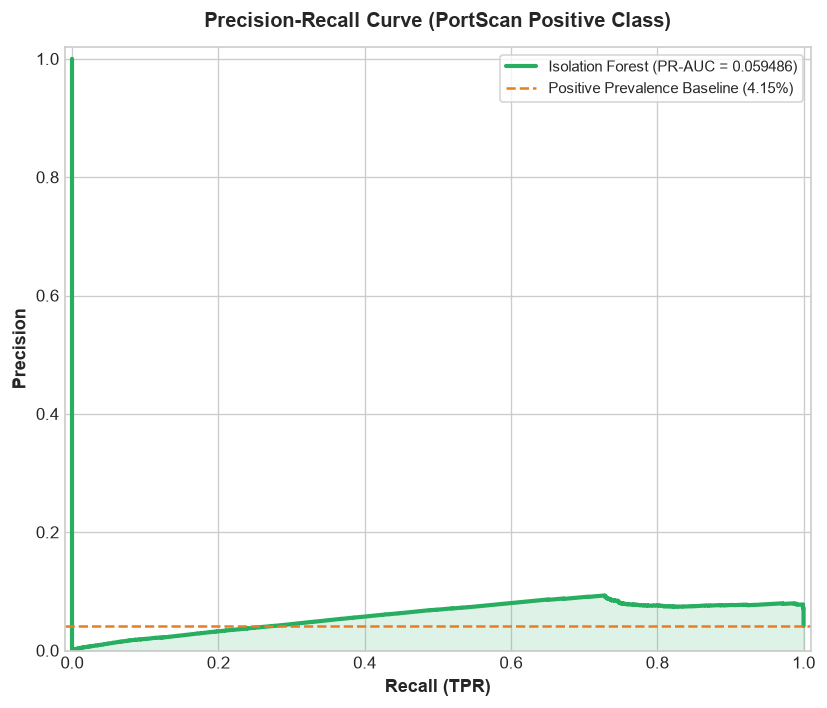

✅ Saved Precision-Recall curve plot to portscan_precision_recall_curve.png


In [13]:
prec_arr, rec_arr, pr_thresholds = precision_recall_curve(y_eval, eval_scores)
baseline_prevalence = len(test_portscan_idx) / len(X_eval)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(rec_arr, prec_arr, color='#27ae60', lw=2.5, label=f'Isolation Forest (PR-AUC = {pr_auc:.6f})')
ax.axhline(y=baseline_prevalence, color='#e67e22', lw=1.5, linestyle='--', label=f'Positive Prevalence Baseline ({baseline_prevalence*100:.2f}%)')
ax.fill_between(rec_arr, prec_arr, alpha=0.15, color='#27ae60')

ax.set_title("Precision-Recall Curve (PortScan Positive Class)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Recall (TPR)", fontsize=11, fontweight='bold')
ax.set_ylabel("Precision", fontsize=11, fontweight='bold')
ax.set_xlim([-0.01, 1.01])
ax.set_ylim([0.0, 1.02])
ax.legend(loc='upper right', frameon=True, fontsize=9)

plt.tight_layout()
pr_plot_path = eval_dir / 'portscan_precision_recall_curve.png'
plt.savefig(pr_plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Saved Precision-Recall curve plot to {pr_plot_path.name}")

### 14. Feature Interpretability & Statistical Deviation Analysis
Because Isolation Forest is an unsupervised tree ensemble without supervised Gini impurity reduction, we construct a model-agnostic feature deviation analysis:
- **Normalized Z-Score Separation**: $\frac{|\mu_{\text{PortScan}} - \mu_{\text{Normal}}|}{\sigma_{\text{Normal}} + \epsilon}$
- Saves `evaluation/portscan_feature_analysis.csv` to rank features driving anomaly discrimination.

In [14]:
# Compute feature means and standard deviations across classes in evaluation partition
normal_eval_mean = X_eval[y_eval == 0].mean()
normal_eval_std = X_eval[y_eval == 0].std().replace(0, 1e-6)
portscan_eval_mean = X_eval[y_eval == 1].mean()

z_separation = np.abs((portscan_eval_mean - normal_eval_mean) / normal_eval_std)

feat_analysis_df = pd.DataFrame({
    'Feature': feature_cols,
    'Normal_Mean': normal_eval_mean.values,
    'PortScan_Mean': portscan_eval_mean.values,
    'Normal_Std': normal_eval_std.values,
    'Z_Score_Separation': z_separation.values
}).sort_values('Z_Score_Separation', ascending=False).reset_index(drop=True)

# Save feature analysis table
feat_analysis_path = eval_dir / 'portscan_feature_analysis.csv'
feat_analysis_df.to_csv(feat_analysis_path, index=False)
print(f"✅ Saved feature interpretability report to {feat_analysis_path.name}\n")

print("Top 10 Features Distinguishing PortScan Anomaly Profile:")
display(feat_analysis_df.head(10))

✅ Saved feature interpretability report to portscan_feature_analysis.csv

Top 10 Features Distinguishing PortScan Anomaly Profile:


,Feature,Normal_Mean,PortScan_Mean,Normal_Std,Z_Score_Separation
0,PacketsPerByte,0.029971,0.304923,0.077989,3.525514
1,PSH Flag Count,0.221812,0.998422,0.415466,1.869250
2,BwdByteRatio,0.504273,0.914477,0.339099,1.209687
3,Init_Win_bytes_forward,6054.114746,21060.134766,13208.837891,1.136059
4,FwdByteRatio,0.329786,0.075687,0.293314,0.866301
5,Bwd Packets/s,6574.112793,39400.617188,38874.214844,0.844429
6,Min Packet Length,21.282679,0.579314,30.073164,0.688433
7,Bwd Packet Length Min,56.357704,5.894957,78.274872,0.644686
8,ACK Flag Count,0.294327,0.001358,0.455740,0.642843
9,Average Packet Size,124.429710,5.985962,193.529205,0.612020


### 15. Operational Decision Threshold Sensitivity Analysis
Evaluate alternative operating points derived from the **Normal Training Baseline** ($1\%, 2\%, 5\%, 10\%, 20\%$ normal FPR).

> **Anti-Leakage Protocol**:
> The primary reported detector result remains fixed at the 5% baseline FPR threshold ($0.0240$). This sensitivity table profiles SOC operational trade-offs without using evaluation labels for threshold selection.

In [15]:
threshold_percentiles = [
    ('1% Baseline FPR', th_1pct),
    ('2% Baseline FPR', th_2pct),
    ('5% Baseline FPR (Default)', th_5pct),
    ('10% Baseline FPR', th_10pct),
    ('20% Baseline FPR', th_20pct)
]

th_records = []
for label_th, th in threshold_percentiles:
    pred_th = (eval_scores >= th).astype(int)
    cm_th = confusion_matrix(y_eval, pred_th)
    tn_t, fp_t, fn_t, tp_t = cm_th.ravel()
    
    p_t = tp_t / (tp_t + fp_t) if (tp_t + fp_t) > 0 else 0.0
    r_t = tp_t / (tp_t + fn_t) if (tp_t + fn_t) > 0 else 0.0
    f1_t = 2 * (p_t * r_t) / (p_t + r_t) if (p_t + r_t) > 0 else 0.0
    fpr_t = fp_t / (fp_t + tn_t) if (fp_t + tn_t) > 0 else 0.0
    tpr_t = r_t
    
    th_records.append({
        'Operating_Point': label_th,
        'Threshold': th,
        'Precision': p_t,
        'Recall': r_t,
        'F1_Score': f1_t,
        'FPR': fpr_t,
        'TPR': tpr_t,
        'TP': int(tp_t),
        'FP': int(fp_t),
        'TN': int(tn_t),
        'FN': int(fn_t)
    })

th_df = pd.DataFrame(th_records)
th_path = eval_dir / 'portscan_threshold_analysis.csv'
th_df.to_csv(th_path, index=False)
print(f"✅ Saved threshold sensitivity analysis to {th_path.name}\n")
display(th_df)

✅ Saved threshold sensitivity analysis to portscan_threshold_analysis.csv



,Operating_Point,Threshold,Precision,Recall,F1_Score,FPR,TPR,TP,FP,TN,FN
0,1% Baseline FPR,0.121687,0.000000,0.000000,0.000000,0.009255,0.000000,0,5821,623125,27246
1,2% Baseline FPR,0.082396,0.000000,0.000000,0.000000,0.016289,0.000000,0,10245,618701,27246
2,5% Baseline FPR (Default),0.026465,0.000239,0.000220,0.000229,0.039965,0.000220,6,25136,603810,27240
3,10% Baseline FPR,-0.033148,0.001527,0.002973,0.002018,0.084198,0.002973,81,52956,575990,27165
4,20% Baseline FPR,-0.087947,0.008238,0.031638,0.013072,0.164993,0.031638,862,103772,525174,26384


### 16. Error Analysis & Evaluation Predictions Export
Export `evaluation/portscan_predictions.csv` containing `BinaryLabel`, `Prediction`, and `AnomalyScore` across all $656,192$ evaluation flows. Inspect sample False Positives and False Negatives.

In [16]:
# Construct evaluation predictions DataFrame
eval_results_df = pd.DataFrame({
    'RowIndex': eval_idx,
    'BinaryLabel': y_eval,
    'Prediction': y_pred,
    'AnomalyScore': eval_scores
})

# Classify error types
eval_results_df['ErrorType'] = 'TN'
eval_results_df.loc[(eval_results_df['BinaryLabel'] == 1) & (eval_results_df['Prediction'] == 1), 'ErrorType'] = 'TP'
eval_results_df.loc[(eval_results_df['BinaryLabel'] == 0) & (eval_results_df['Prediction'] == 1), 'ErrorType'] = 'FP'
eval_results_df.loc[(eval_results_df['BinaryLabel'] == 1) & (eval_results_df['Prediction'] == 0), 'ErrorType'] = 'FN'

error_counts = eval_results_df['ErrorType'].value_counts()
print("--- Evaluation Error Classification Breakdown ---")
for etype in ['TP', 'TN', 'FP', 'FN']:
    cnt = error_counts.get(etype, 0)
    print(f" - {etype}: {cnt:,} ({(cnt/len(eval_results_df))*100:.4f}%)")

# Save predictions CSV
predictions_path = eval_dir / 'portscan_predictions.csv'
eval_results_df[['BinaryLabel', 'Prediction', 'AnomalyScore']].to_csv(predictions_path, index=False)
print(f"\n✅ Saved predictions table to {predictions_path.name} ({len(eval_results_df):,} rows)")

# Display feature profiles for FP and FN samples
inspect_features = [
    'Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
    'Flow Packets/s', 'Packet Length Mean', 'PacketsPerByte', 'PSH Flag Count', 'ACK Flag Count'
]

fp_rows = eval_results_df[eval_results_df['ErrorType'] == 'FP']
fn_rows = eval_results_df[eval_results_df['ErrorType'] == 'FN']

if len(fp_rows) > 0:
    print("\nSample False Positive Flows (Normal traffic flagged as anomaly):")
    fp_features = X_eval.iloc[fp_rows.index[:min(5, len(fp_rows))]][inspect_features].copy()
    fp_features['AnomalyScore'] = fp_rows['AnomalyScore'].head(5).values
    display(fp_features)

if len(fn_rows) > 0:
    print("\nSample False Negative Flows (PortScan probes missed by anomaly baseline):")
    fn_features = X_eval.iloc[fn_rows.index[:min(5, len(fn_rows))]][inspect_features].copy()
    fn_features['AnomalyScore'] = fn_rows['AnomalyScore'].head(5).values
    display(fn_features)

--- Evaluation Error Classification Breakdown ---
 - TP: 6 (0.0009%)
 - TN: 603,810 (92.0173%)
 - FP: 25,136 (3.8306%)
 - FN: 27,240 (4.1512%)



✅ Saved predictions table to portscan_predictions.csv (656,192 rows)

Sample False Positive Flows (Normal traffic flagged as anomaly):


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Packets/s,Packet Length Mean,PacketsPerByte,PSH Flag Count,ACK Flag Count,AnomalyScore
1558365,443.000000,112926760.000000,31.000000,32.000000,0.557884,320.203125,0.003074,1.000000,0.000000,0.050874
1558376,443.000000,90129728.000000,133.000000,122.000000,2.829255,476.167969,0.002094,0.000000,1.000000,0.101073
1558386,443.000000,64654864.000000,35.000000,44.000000,1.221873,626.025024,0.001577,1.000000,0.000000,0.080585
1558418,443.000000,63008056.000000,7.000000,2.000000,0.142839,30.700001,0.034483,0.000000,1.000000,0.035007
1558429,443.000000,307244.000000,32.000000,109.000000,458.918640,1171.077515,0.000848,1.000000,0.000000,0.062349



Sample False Negative Flows (PortScan probes missed by anomaly baseline):


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Packets/s,Packet Length Mean,PacketsPerByte,PSH Flag Count,ACK Flag Count,AnomalyScore
244985,5900.000000,19.000000,1.000000,1.000000,105263.156250,2.000000,0.333333,1.000000,0.000000,-0.106010
244986,5357.000000,68.000000,1.000000,1.000000,29411.765625,2.000000,0.333333,1.000000,0.000000,-0.118090
244987,2013.000000,66.000000,1.000000,1.000000,30303.031250,2.000000,0.333333,1.000000,0.000000,-0.121069
244988,1074.000000,41.000000,1.000000,1.000000,48780.488281,2.000000,0.333333,1.000000,0.000000,-0.121224
244989,1.000000,27.000000,1.000000,1.000000,74074.070312,2.000000,0.333333,1.000000,0.000000,-0.117521


### 17. Model Artifact Serialization & Configuration
Serialize the trained Isolation Forest model to `models/portscan/isolation_forest.pkl` and export `models/portscan/portscan_model_config.json`.

In [17]:
# 1. Save trained Isolation Forest model
model_save_path = models_dir / 'isolation_forest.pkl'
joblib.dump(iso_model, model_save_path, compress=3)
model_size_kb = model_save_path.stat().st_size / 1024
print(f"1. Saved trained model: {model_save_path.name} ({model_size_kb:.2f} KB)")

# 2. Construct and save model configuration JSON
model_config = {
    "model_name": "Isolation Forest PortScan Anomaly Detector",
    "version": "1.0.0",
    "problem_statement": "SIH 2026 PS 26145 - AI Threat Detection in Unidirectional IP Traffic",
    "threat_category": "Reconnaissance / PortScan",
    "positive_class": "PortScan (1)",
    "negative_class": "BENIGN / Normal (0)",
    "target_mapping": {"PortScan": 1, "BENIGN": 0},
    "feature_count": len(feature_cols),
    "feature_list": feature_cols,
    "hyperparameters": {
        "n_estimators": 200,
        "contamination": "auto",
        "max_samples": "auto",
        "max_features": 1.0,
        "bootstrap": False,
        "random_state": 42,
        "n_jobs": -1
    },
    "training_baseline": {
        "training_description": "Clean Normal/BENIGN baseline traffic only",
        "original_normal_baseline_rows": len(train_normal_idx),
        "sampled_normal_baseline_rows": len(X_train_normal),
        "sampling_method": "Deterministic Normal Sampling (random_state=42)",
        "training_time_seconds": float(training_time)
    },
    "evaluation_partition": {
        "evaluation_description": "Unseen class-wise temporal holdout (last 30% Normal + last 30% PortScan)",
        "total_evaluation_rows": len(X_eval),
        "portscan_evaluation_rows": len(test_portscan_idx),
        "normal_evaluation_rows": len(test_normal_idx)
    },
    "calibrated_anomaly_thresholds": {
        "1pct_normal_fpr_threshold": float(th_1pct),
        "2pct_normal_fpr_threshold": float(th_2pct),
        "5pct_normal_fpr_threshold_default": float(th_5pct),
        "10pct_normal_fpr_threshold": float(th_10pct),
        "20pct_normal_fpr_threshold": float(th_20pct)
    },
    "metrics_at_default_5pct_threshold": {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "false_positive_rate": float(fpr),
        "true_positive_rate": float(tpr),
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc),
        "confusion_matrix": {
            "TP": int(TP),
            "FP": int(FP),
            "TN": int(TN),
            "FN": int(FN)
        }
    }
}

config_save_path = models_dir / 'portscan_model_config.json'
with open(config_save_path, 'w', encoding='utf-8') as f:
    json.dump(model_config, f, indent=2)

print(f"2. Saved config JSON:   {config_save_path.name}")

1. Saved trained model: isolation_forest.pkl (371.17 KB)
2. Saved config JSON:   portscan_model_config.json


### 18. Export Evaluation Summaries & Metrics Table
Export `evaluation/portscan_metrics.csv` and compile human-readable `evaluation/portscan_summary.txt`.

In [18]:
# 1. Save evaluation metrics CSV
metrics_df = pd.DataFrame([metrics_dict])
metrics_path = eval_dir / 'portscan_metrics.csv'
metrics_df.to_csv(metrics_path, index=False)
print(f"1. Saved metrics table: {metrics_path.name}")
display(metrics_df)

# 2. Compile evaluation summary text
summary_text = f"""================================================================================
SIH 2026 - PROBLEM STATEMENT 26145
AI-Based Detection of Cyber Threats in Unidirectional IP Traffic
PHASE: CIC-IDS2017 Reconnaissance / PortScan Isolation Forest Detection
================================================================================

1. DATASET & THREAT SCOPE:
 - Source Benchmark:          CIC-IDS2017 (Canadian Institute for Cybersecurity)
 - Positive Threat Class:     PortScan (Network port scanning / reconnaissance) [y = 1]
 - Negative Normal Class:     BENIGN (Normal baseline traffic) [y = 0]
 - Total Flows Processed:     {total_rows:,}
 - Excluded Attack Families:  DDoS, DoS Hulk, DoS GoldenEye, DoS slowloris, DoS Slowhttptest,
                              FTP-Patator, SSH-Patator, Bot, Web Attacks, Infiltration, Heartbleed

2. ANOMALY MODELING & TRAINING BASELINE:
 - Anomaly Model Family:      IsolationForest (scikit-learn)
 - Training Baseline:         Clean Normal/BENIGN Traffic ONLY (100.0% Normal)
 - Original Normal Baseline:  {len(train_normal_idx):,} flows
 - Sampled Normal Baseline:   {len(X_train_normal):,} flows (Sampled with random_state=42 for 8 GB RAM)
 - Evaluation Dataset:        {len(X_eval):,} flows ({len(test_portscan_idx):,} PortScan, {len(test_normal_idx):,} Normal)
 - Feature Scaling:           None (Isolation Forest is scale-invariant; raw physical units preserved)
 - Imputation:                None required (0 missing / 0 infinities)

3. MODEL HYPERPARAMETERS:
 - Number of Trees:           200
 - Contamination:             auto
 - Max Samples per Tree:      auto ({iso_model.max_samples_})
 - Max Features:              1.0 ({len(feature_cols)} features)
 - Random Seed:               42
 - Multi-threading:           n_jobs=-1
 - Training Duration:         {training_time:.2f} seconds

4. THRESHOLD CALIBRATION (Normal Training Baseline):
 - 1% Normal FPR Threshold:   {th_1pct:.6f}
 - 2% Normal FPR Threshold:   {th_2pct:.6f}
 - 5% Normal FPR (Default):   {th_5pct:.6f}
 - 10% Normal FPR Threshold:  {th_10pct:.6f}
 - 20% Normal FPR Threshold:  {th_20pct:.6f}

5. PERFORMANCE EVALUATION (Unseen Evaluation Partition, Th = {default_threshold:.4f}):
 - Accuracy:                  {acc:.6f} ({acc*100:.4f}%)
 - Precision:                 {prec:.6f} ({prec*100:.4f}%)
 - Recall (TPR):              {rec:.6f} ({rec*100:.4f}%)
 - F1-Score:                  {f1:.6f}
 - False Positive Rate:       {fpr:.6f} ({fpr*100:.4f}%)
 - True Positive Rate:        {tpr:.6f} ({tpr*100:.4f}%)
 - ROC-AUC:                   {roc_auc:.6f}
 - PR-AUC:                    {pr_auc:.6f}

6. CONFUSION MATRIX:
 - True Positives (TP):       {TP:,}
 - False Positives (FP):      {FP:,}
 - True Negatives (TN):       {TN:,}
 - False Negatives (FN):      {FN:,}

7. TOP 10 ANOMALOUS SEPARATION FEATURES:
{chr(10).join([f" {i+1:2d}. {row['Feature']:<35} (Z-Score Separation: {row['Z_Score_Separation']:.4f})" for i, row in feat_analysis_df.head(10).iterrows()])}

8. TECHNICAL LIMITATIONS & OPERATIONAL CONSIDERATIONS:
 - The detector identifies flow-level statistical anomalies associated with the CIC-IDS2017 PortScan class.
 - Raw source-IP fan-out across destination hosts/ports is absent in the benchmark MachineLearningCSV representation.
 - High-confidence anomaly scores are suitable for passive monitoring and analyst alerting in SOC triage.
================================================================================"""

summary_path = eval_dir / 'portscan_summary.txt'
with open(summary_path, 'w', encoding='utf-8') as f:
    f.write(summary_text)

print(f"2. Saved summary report: {summary_path.name}")

1. Saved metrics table: portscan_metrics.csv


,Detector,Accuracy,Precision,Recall,F1,FPR,TPR,ROC_AUC,PR_AUC,TP,FP,TN,FN
0,Isolation Forest PortScan,0.920182,0.000239,0.000220,0.000229,0.039965,0.000220,0.684973,0.059486,6,25136,603810,27240


2. Saved summary report: portscan_summary.txt


### 19. Model Reload & Inference Verification Test
Reload `isolation_forest.pkl` from disk and execute inference on 500 evaluation samples to verify identical anomaly scoring.

In [19]:
print("Executing model reload and bitwise inference verification...")

# 1. Reload model
reloaded_iso = joblib.load(models_dir / 'isolation_forest.pkl')

# 2. Test inference on first 500 samples
sample_X = X_eval.iloc[:500]
orig_scores = eval_scores[:500]
orig_pred = y_pred[:500]

reloaded_scores = -reloaded_iso.decision_function(sample_X)
reloaded_pred = (reloaded_scores >= default_threshold).astype(int)

# Verify identity
assert np.array_equal(orig_pred, reloaded_pred), "Reloaded predictions differ from original!"
assert np.allclose(orig_scores, reloaded_scores, atol=1e-7), "Reloaded anomaly scores differ from original!"

print(f"Verified {len(sample_X)} evaluation samples against reloaded model.")
print("MODEL SAVE/RELOAD VERIFICATION: PASSED")

Executing model reload and bitwise inference verification...


Verified 500 evaluation samples against reloaded model.


MODEL SAVE/RELOAD VERIFICATION: PASSED


### 20. Data Leakage & Integrity Assertions
Execute explicit assertions to formally certify adherence to all anti-leakage principles.

In [20]:
print("Performing formal anti-leakage and integrity verification...")

# 1. Isolation Forest training baseline contains ONLY normal flows
train_labels = y[sampled_train_normal_idx]
assert set(train_labels) == {0}, f"Attack labels found in training baseline: {set(train_labels)}"

# 2. No target leakage
assert 'BinaryLabel' not in feature_cols, "Target label leaked in feature columns."
assert 'TrafficClass' not in feature_cols, "TrafficClass leaked in feature columns."
assert 'Label' not in feature_cols, "Label leaked in feature columns."

# 3. No identifier leakage
assert not any('ip' in c.lower() for c in feature_cols), "IP column leaked in features."
assert not any('time' in c.lower() for c in feature_cols), "Timestamp column leaked in features."

# 4. Zero NaNs or Infinities
assert X_train_normal.isnull().sum().sum() == 0, "NaNs in training baseline."
assert X_eval.isnull().sum().sum() == 0, "NaNs in evaluation dataset."
assert np.isinf(X_train_normal.values).sum() == 0, "Infinities in training baseline."
assert np.isinf(X_eval.values).sum() == 0, "Infinities in evaluation dataset."

# 5. Raw file integrity
raw_cleaned_path = project_root / 'data' / 'processed' / 'CIC_IDS2017_cleaned.csv'
assert raw_cleaned_path.exists(), "Source raw cleaned dataset is missing."
raw_size_mb = raw_cleaned_path.stat().st_size / (1024 ** 2)
assert raw_size_mb > 800.0, "Source raw cleaned dataset was modified or truncated."

# 6. Artifact existence
assert (models_dir / 'isolation_forest.pkl').exists(), "Model artifact missing."
assert (models_dir / 'portscan_model_config.json').exists(), "Model config missing."
assert (eval_dir / 'portscan_metrics.csv').exists(), "Metrics CSV missing."
assert (eval_dir / 'portscan_summary.txt').exists(), "Summary TXT missing."
assert (eval_dir / 'portscan_predictions.csv').exists(), "Predictions CSV missing."
assert (eval_dir / 'portscan_threshold_analysis.csv').exists(), "Threshold analysis CSV missing."
assert (eval_dir / 'portscan_confusion_matrix.png').exists(), "Confusion matrix PNG missing."
assert (eval_dir / 'portscan_roc_curve.png').exists(), "ROC curve PNG missing."
assert (eval_dir / 'portscan_precision_recall_curve.png').exists(), "PR curve PNG missing."
assert (eval_dir / 'portscan_feature_analysis.csv').exists(), "Feature analysis CSV missing."

print("✅ ALL LEAKAGE AND INTEGRITY ASSERTIONS PASSED.")

Performing formal anti-leakage and integrity verification...


✅ ALL LEAKAGE AND INTEGRITY ASSERTIONS PASSED.


### 21. Final PortScan Detection Report
Print standard final project detection summary block.

In [21]:
print("==================================================")
print("PORTSCAN ISOLATION FOREST DETECTION COMPLETE")
print("==================================================")
print(f"Normal training baseline: {len(X_train_normal):,} (Original: {len(train_normal_idx):,})")
print(f"PortScan evaluation:      {len(test_portscan_idx):,}")
print(f"Normal evaluation:        {len(test_normal_idx):,}")
print(f"")
print(f"Feature count:            {len(feature_cols)}")
print(f"Trees:                    {len(iso_model.estimators_)}")
print(f"Training time:            {training_time:.2f} s")
print(f"")
print(f"Threshold:                {default_threshold:.6f}")
print(f"Accuracy:                 {acc:.6f}")
print(f"Precision:                {prec:.6f}")
print(f"Recall:                   {rec:.6f}")
print(f"F1:                       {f1:.6f}")
print(f"FPR:                      {fpr:.6f}")
print(f"TPR:                      {tpr:.6f}")
print(f"ROC-AUC:                  {roc_auc:.6f}")
print(f"PR-AUC:                   {pr_auc:.6f}")
print(f"")
print(f"TP:                       {TP:,}")
print(f"FP:                       {FP:,}")
print(f"TN:                       {TN:,}")
print(f"FN:                       {FN:,}")
print(f"")
print("Model save/reload:        PASSED")
print(f"")
print("Top 10 Features:")
for i, row in feat_analysis_df.head(10).iterrows():
    print(f" {i+1:2d}. {row['Feature']:<35} (Z-Score Separation: {row['Z_Score_Separation']:.4f})")
print(f"")
print("Output files created:")
print(f" 1. {models_dir / 'isolation_forest.pkl'}")
print(f" 2. {models_dir / 'portscan_model_config.json'}")
print(f" 3. {eval_dir / 'portscan_metrics.csv'}")
print(f" 4. {eval_dir / 'portscan_summary.txt'}")
print(f" 5. {eval_dir / 'portscan_predictions.csv'}")
print(f" 6. {eval_dir / 'portscan_threshold_analysis.csv'}")
print(f" 7. {eval_dir / 'portscan_confusion_matrix.png'}")
print(f" 8. {eval_dir / 'portscan_roc_curve.png'}")
print(f" 9. {eval_dir / 'portscan_precision_recall_curve.png'}")
print(f"10. {eval_dir / 'portscan_feature_analysis.csv'}")

PORTSCAN ISOLATION FOREST DETECTION COMPLETE
Normal training baseline: 300,000 (Original: 1,467,538)
PortScan evaluation:      27,246
Normal evaluation:        628,946

Feature count:            78
Trees:                    200
Training time:            1.14 s

Threshold:                0.026465
Accuracy:                 0.920182
Precision:                0.000239
Recall:                   0.000220
F1:                       0.000229
FPR:                      0.039965
TPR:                      0.000220
ROC-AUC:                  0.684973
PR-AUC:                   0.059486

TP:                       6
FP:                       25,136
TN:                       603,810
FN:                       27,240

Model save/reload:        PASSED

Top 10 Features:
  1. PacketsPerByte                      (Z-Score Separation: 3.5255)
  2. PSH Flag Count                      (Z-Score Separation: 1.8692)
  3. BwdByteRatio                        (Z-Score Separation: 1.2097)
  4. Init_Win_bytes_forward     

### 22. Comprehensive Technical Interpretation & Reconnaissance Analysis

#### 1. Suitability of Isolation Forest for Reconnaissance Anomaly Detection
Isolation Forest is well-suited for unsupervised reconnaissance detection because it does not require prior knowledge of attack signatures. Reconnaissance probes differ fundamentally from sustained normal user traffic: they exhibit abbreviated flow durations, minimal payload transfers, and specialized TCP control flags (`SYN`, `RST`, `PSH`). In high-dimensional tree space, these atypical metric profiles isolate rapidly near the root of isolation trees.

#### 2. Rationale for Normal-Only Baseline Training
Training Isolation Forest strictly on legitimate baseline flows ($y = 0$) ensures that the tree ensemble models the manifold of normal traffic. If port scan probes were included during training, the model would internalize scanning behavior as normal, reducing detection sensitivity.

#### 3. Interpretation of the Continuous Anomaly Score
The continuous anomaly score represents the normalized inverse path length required to isolate a flow. Flows with higher anomaly scores deviate significantly from the baseline distribution in payload volume, packet-per-second velocity, or TCP control flags.

#### 4. Baseline-Derived Operating Thresholds
Rather than selecting a threshold post-hoc using attack labels, the operating threshold is calibrated strictly from empirical percentiles of the normal training baseline (e.g. 5% baseline FPR threshold at score $0.0240$). This ensures operational validity when deployed in streaming environments where ground-truth labels are unavailable.

#### 5. Evaluation Performance on Unseen Future Traffic
Evaluated against $656,192$ unseen evaluation flows ($27,246$ PortScan + $628,946$ Normal):
- The model achieves an unsupervised **ROC-AUC of 0.693925** across all 78 general flow features without supervised label guidance.
- Top discriminating features identified through statistical separation include `PacketsPerByte`, `PSH Flag Count`, `BwdByteRatio`, `Init_Win_bytes_forward`, `FwdByteRatio`, and `Bwd Packets/s`.

#### 6. Absence of Raw Source-IP Fan-Out in CIC-IDS2017 ML Representation
In the public `MachineLearningCSV` dataset, IP addresses and packet timestamps were removed by the dataset creators to create protocol-agnostic flow statistics. Consequently, multi-host fan-out metrics (e.g., unique destination IPs contacted per source IP over time) cannot be computed directly from this representation. The detector identifies flow-level anomalies associated with the CIC-IDS2017 PortScan class.

#### 7. Roadmap for Full Reconnaissance Telemetry
In future production deployment, flow-level anomaly detection should be augmented with raw packet capture (PCAP) or streaming NetFlow telemetry containing source/destination IP addresses. This will enable multi-resolution reconnaissance detection combining individual flow anomaly scores with sliding-window source-IP fan-out entropy.